In [1]:
import os, sys, warnings
sys.path.append(os.path.abspath(".."))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import sqlite3
import joblib
from datetime import datetime

PROPHET_OK = False
try:
    from prophet import Prophet
    PROPHET_OK = True
    print(" Prophet available — using Prophet for forecasting")
except Exception as e:
    print(" Prophet NOT available — falling back to SARIMA (statsmodels)")
    print("   Reason:", e)
    print("   To install Prophet on Windows:")
    print("   Option A: pip install prophet==1.1.5")
    print("   Option B: conda install -c conda-forge prophet")
    from statsmodels.tsa.statespace.sarimax import SARIMAX

MODEL_VERSION = "v1.0-prophet" if PROPHET_OK else "v1.0-sarima"
FORECAST_HORIZONS = [7, 30, 60]   # we serve all three

 Prophet available — using Prophet for forecasting


In [2]:
# Load 3 years of sales from SQLite (joins)

conn = sqlite3.connect("../logistics.db")
df = pd.read_sql_query("""
    SELECT sh.date, sh.sku_id, sh.warehouse_id, sh.qty_sold,
           s.sku_code, s.name AS sku_name, s.category, s.unit_cost, s.lead_time_days,
           w.name AS warehouse_name, w.city
    FROM sales_history sh
    JOIN skus s       ON sh.sku_id = s.id
    JOIN warehouses w ON sh.warehouse_id = w.id
""", conn)
print(f"Loaded {len(df):,} rows")
df["date"] = pd.to_datetime(df["date"])
print("Date range:", df["date"].min().date(), "→", df["date"].max().date())
print("Distinct SKUs:", df["sku_id"].nunique(),
      "| Warehouses:", df["warehouse_id"].nunique())
df.head()

Loaded 1,087,626 rows
Date range: 2023-10-20 → 2026-10-19
Distinct SKUs: 100 | Warehouses: 10


,date,sku_id,warehouse_id,qty_sold,sku_code,sku_name,category,unit_cost,lead_time_days,warehouse_name,city
0,2023-10-20,1,1,34,SKU-1001,Wireless Earbuds (Ele-1),Electronics,1403.88,3,WH-Mumbai,Mumbai
1,2023-10-20,1,2,51,SKU-1001,Wireless Earbuds (Ele-1),Electronics,1403.88,3,WH-Delhi,Delhi
2,2023-10-20,1,3,21,SKU-1001,Wireless Earbuds (Ele-1),Electronics,1403.88,3,WH-Bengaluru,Bengaluru
3,2023-10-20,1,4,28,SKU-1001,Wireless Earbuds (Ele-1),Electronics,1403.88,3,WH-Chennai,Chennai
4,2023-10-20,1,5,26,SKU-1001,Wireless Earbuds (Ele-1),Electronics,1403.88,3,WH-Kolkata,Kolkata


In [3]:
# Aggregate per (SKU, warehouse) daily totals 
# Force dtype + safe gap-fill

# daily = (df.groupby(["sku_id", "warehouse_id", "date"], as_index=False)
#            .agg(y=("qty_sold", "sum")))
# # Ensure contiguous dates (fill gaps with 0) — critical for Prophet
# full_idx = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
# groups = []
# for (sku, wh), g in daily.groupby(["sku_id", "warehouse_id"]):
#     g = g.set_index("date").reindex(full_idx, fill_value=0).rename_axis("date").reset_index()
#     g["sku_id"] = sku
#     g["warehouse_id"] = wh
#     groups.append(g)
# daily = pd.concat(groups, ignore_index=True)
# print(f"Regridded to {len(daily):,} rows across {daily.groupby(['sku_id','warehouse_id']).ngroups} series")


# Aggregate per (SKU, warehouse) daily totals
daily = (df.groupby(["sku_id", "warehouse_id", "date"], as_index=False)
           .agg(y=("qty_sold", "sum")))

# CRITICAL: force datetime dtype — this is what was silently breaking
daily["date"] = pd.to_datetime(daily["date"], errors="coerce")
daily = daily.dropna(subset=["date"])
daily["date"] = daily["date"].dt.normalize()   # strip time component

# Ensure contiguous dates per series (fill missing with 0)
full_idx = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
groups = []
for (sku, wh), g in daily.groupby(["sku_id", "warehouse_id"]):
    g = (g.set_index("date")
          .reindex(full_idx, fill_value=0)
          .reset_index()
          .rename(columns={"index": "date"}))
    # double-guard: force dtype again after reindex
    g["date"] = pd.to_datetime(g["date"], errors="coerce")
    g = g.dropna(subset=["date"])
    g["sku_id"] = sku
    g["warehouse_id"] = wh
    groups.append(g[["date", "sku_id", "warehouse_id", "y"]])

daily = pd.concat(groups, ignore_index=True)
print(f"Regridded to {len(daily):,} rows across "
      f"{daily.groupby(['sku_id','warehouse_id']).ngroups} series")
print("dtype check:", daily["date"].dtype, "| sample:", daily["date"].iloc[0])
# Expected: datetime64[ns]  | sample: 2022-10-18 00:00:00

Regridded to 1,096,000 rows across 1000 series
dtype check: datetime64[us] | sample: 2023-10-20 00:00:00


In [4]:
# Helper: fit Prophet or SARIMA, return forecast df
# Defensive fit_and_forecast

# def fit_and_forecast(series_df, horizon_days):
#     """series_df: DataFrame with 'ds' and 'y' columns (daily)."""
#     cutoff = series_df["ds"].max() - pd.Timedelta(days=30)
#     train = series_df[series_df["ds"] <= cutoff]
#     test  = series_df[series_df["ds"] > cutoff]

#     if PROPHET_OK:
#         m = Prophet(
#             daily_seasonality=False,
#             weekly_seasonality=True,
#             yearly_seasonality=True,
#             changepoint_prior_scale=0.05,
#             interval_width=0.80,
#         )
#         m.fit(train[["ds", "y"]])
#         future = m.make_future_dataframe(periods=len(test) + horizon_days, freq="D")
#         fcst = m.predict(future)
#         pred_test = fcst[fcst["ds"].isin(test["ds"])]["yhat"].values
#         y_true    = test["y"].values
#         future_fc = fcst[fcst["ds"] > series_df["ds"].max()][["ds","yhat","yhat_lower","yhat_upper"]].tail(horizon_days)
#         model_obj = m
#     else:
#         # SARIMA fallback (weekly seasonality = 7)
#         try:
#             mod = SARIMAX(train["y"].values,
#                           order=(1,1,1), seasonal_order=(1,1,1,7),
#                           enforce_stationarity=False, enforce_invertibility=False)
#             res = mod.fit(disp=False)
#             n_test = len(test)
#             pred_test = res.forecast(n_test)
#             y_true = test["y"].values
#             fc = res.get_forecast(horizon_days)
#             mean = fc.predicted_mean
#             ci   = fc.conf_int(alpha=0.20)
#             last_date = series_df["ds"].max()
#             future_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=horizon_days, freq="D")
#             future_fc = pd.DataFrame({
#                 "ds": future_dates,
#                 "yhat": mean,
#                 "yhat_lower": ci[:, 0],
#                 "yhat_upper": ci[:, 1],
#             })
#             model_obj = res
#         except Exception:
#             future_fc = pd.DataFrame({
#                 "ds": pd.date_range(series_df["ds"].max() + pd.Timedelta(days=1),
#                                     periods=horizon_days, freq="D"),
#                 "yhat": [series_df["y"].tail(30).mean()] * horizon_days,
#                 "yhat_lower": [0] * horizon_days,
#                 "yhat_upper": [series_df["y"].tail(30).mean() * 1.5] * horizon_days,
#             })
#             model_obj = None
#             y_true = test["y"].values
#             pred_test = np.full(len(test), series_df["y"].tail(30).mean())

#     # clip negatives
#     future_fc = future_fc.clip(lower=0)
#     pred_test = np.clip(pred_test, 0, None)

#     # metrics
#     mask = y_true > 0
#     if mask.sum() > 0:
#         mape = float(np.mean(np.abs((y_true[mask] - pred_test[mask]) / y_true[mask])) * 100)
#     else:
#         mape = None
#     mae = float(np.mean(np.abs(y_true - pred_test))) if len(y_true) else None

#     return future_fc, mape, mae, model_obj


# Defensive fit_and_forecast
# def fit_and_forecast(series_df, horizon_days):
#     """series_df: DataFrame with 'ds' and 'y' (daily). Returns (future_fc, mape, mae, model)."""
#     # ---- hard guards (this is the fix) ----
#     series_df = series_df.copy()
#     series_df["ds"] = pd.to_datetime(series_df["ds"], errors="coerce")
#     series_df = series_df.dropna(subset=["ds"]).sort_values("ds").reset_index(drop=True)
#     series_df["y"] = pd.to_numeric(series_df["y"], errors="coerce").fillna(0)

#     if series_df.empty or len(series_df) < 200:
#         raise ValueError(f"series too short ({len(series_df)} rows)")

#     cutoff = series_df["ds"].max() - pd.Timedelta(days=30)
#     train  = series_df[series_df["ds"] <= cutoff]
#     test   = series_df[series_df["ds"] >  cutoff]

#     if len(train) < 100 or len(test) < 5:
#         raise ValueError(f"train/test split too small (train={len(train)}, test={len(test)})")

#     if PROPHET_OK:
#         m = Prophet(
#             daily_seasonality=False,
#             weekly_seasonality=True,
#             yearly_seasonality=True,
#             changepoint_prior_scale=0.05,
#             interval_width=0.80,
#         )
#         m.fit(train[["ds", "y"]])
#         future = m.make_future_dataframe(periods=len(test) + horizon_days, freq="D")
#         fcst   = m.predict(future)

#         pred_test = fcst[fcst["ds"].isin(test["ds"])]["yhat"].values
#         y_true    = test["y"].values
#         future_fc = (fcst[fcst["ds"] > series_df["ds"].max()]
#                      [["ds", "yhat", "yhat_lower", "yhat_upper"]]
#                      .tail(horizon_days))
#         model_obj = m
#     else:
#         from statsmodels.tsa.statespace.sarimax import SARIMAX
#         mod = SARIMAX(train["y"].values, order=(1, 1, 1),
#                       seasonal_order=(1, 1, 1, 7),
#                       enforce_stationarity=False, enforce_invertibility=False)
#         res = mod.fit(disp=False)
#         pred_test = res.forecast(len(test))
#         y_true    = test["y"].values

#         fc = res.get_forecast(horizon_days)
#         mean = fc.predicted_mean
#         ci   = fc.conf_int(alpha=0.20)
#         last_date = series_df["ds"].max()
#         future_dates = pd.date_range(last_date + pd.Timedelta(days=1),
#                                      periods=horizon_days, freq="D")
#         future_fc = pd.DataFrame({
#             "ds": future_dates,
#             "yhat": mean,
#             "yhat_lower": ci[:, 0],
#             "yhat_upper": ci[:, 1],
#         })
#         model_obj = res

#     future_fc = future_fc.clip(lower=0)
#     pred_test = np.clip(pred_test, 0, None)

#     mask = y_true > 0
#     mape = (float(np.mean(np.abs((y_true[mask] - pred_test[mask]) / y_true[mask])) * 100)
#             if mask.sum() > 0 else None)
#     mae  = float(np.mean(np.abs(y_true - pred_test))) if len(y_true) else None

#     return future_fc, mape, mae, model_obj


def _to_naive_utc(s):
    """Force any datetime-like Series to naive datetime64[ns]."""
    s = pd.to_datetime(s, errors="coerce", utc=True)
    return s.dt.tz_localize(None).astype("datetime64[ns]")


def _as_float(s):
    """Force any numeric-like Series to float64, treating None as NaN."""
    return pd.to_numeric(s, errors="coerce").astype("float64")


def fit_and_forecast(series_df, horizon_days):
    """series_df: DataFrame with 'ds','y'. Returns (future_fc, mape, mae, model)."""
    # ---- normalise input (dtype is now guaranteed at both ends) ----
    s = pd.DataFrame({
        "ds": _to_naive_utc(series_df["ds"]),
        "y":  _as_float(series_df["y"]).fillna(0.0),
    }).dropna(subset=["ds"]).sort_values("ds").reset_index(drop=True)

    if len(s) < 200:
        raise ValueError(f"series too short ({len(s)} rows)")
    if s["y"].sum() < 50:
        raise ValueError(f"series too sparse (sum={s['y'].sum():.0f})")

    last_ds = s["ds"].max()
    cutoff  = last_ds - pd.Timedelta(days=30)

    train = s[s["ds"] <= cutoff][["ds", "y"]].reset_index(drop=True)
    test  = s[s["ds"] >  cutoff][["ds", "y"]].reset_index(drop=True)

    if len(train) < 100 or len(test) < 5:
        raise ValueError(f"split too small (train={len(train)}, test={len(test)})")

    # ============================================================
    # PROPHET 1.5.0 PATH
    # ============================================================
    if PROPHET_OK:
        try:
            m = Prophet(
                weekly_seasonality=True,
                yearly_seasonality=True,
                changepoint_prior_scale=0.05,
                interval_width=0.80,
            )
            # NOTE: daily_seasonality=... is intentionally omitted —
            # Prophet 1.5 handles daily=False by default for daily data.

            m.fit(train)

            # build future and RE-FORCE dtype right after generation
            future = m.make_future_dataframe(
                periods=len(test) + int(horizon_days),
                freq="D",
                include_history=True,
            )
            future["ds"] = _to_naive_utc(future["ds"])

            fcst = m.predict(future)

            # Prophet 1.5 output — force dtype back to ns before any pandas ops
            fcst["ds"]         = _to_naive_utc(fcst["ds"])
            fcst["yhat"]       = _as_float(fcst["yhat"])
            fcst["yhat_lower"] = _as_float(fcst["yhat_lower"])
            fcst["yhat_upper"] = _as_float(fcst["yhat_upper"])

            # ---- match test dates by REINDEX, not by isin ----
            fcst_idx = fcst.set_index("ds")
            pred_test = (
                fcst_idx
                .reindex(test["ds"])["yhat"]
                .fillna(train["y"].mean())
                .to_numpy(dtype=float)
            )
            y_true = test["y"].to_numpy(dtype=float)

            # ---- future slice ----
            future_only = (
                fcst[fcst["ds"] > last_ds]
                .sort_values("ds")
                .tail(int(horizon_days))
                .reset_index(drop=True)
            )
            if future_only.empty:
                raise ValueError("Prophet returned no future rows")
            future_fc = future_only[["ds", "yhat", "yhat_lower", "yhat_upper"]]
            model_obj = m

        except Exception as e_prophet:
            print(f"    Prophet failed ({type(e_prophet).__name__}: {e_prophet}); "
                  f"trying SARIMA")
            return _sarima_forecast(train, test, horizon_days, last_ds)

    else:
        return _sarima_forecast(train, test, horizon_days, last_ds)

    # ---- clip + metrics (safe for Prophet 1.5 output) ----
    future_fc = future_fc.copy()
    for col in ("yhat", "yhat_lower", "yhat_upper"):
        future_fc[col] = future_fc[col].astype("float64").clip(lower=0)
    pred_test = np.clip(pred_test, 0, None)

    mask = y_true > 0
    mape = (float(np.mean(np.abs((y_true[mask] - pred_test[mask]) / y_true[mask])) * 100)
            if mask.sum() > 0 else None)
    mae  = float(np.mean(np.abs(y_true - pred_test))) if len(y_true) else None

    return future_fc, mape, mae, model_obj


def _sarima_forecast(train, test, horizon_days, last_ds):
    """Shared SARIMA fallback. Returns (future_fc, mape, mae, model)."""
    from statsmodels.tsa.statespace.sarimax import SARIMAX

    try:
        mod = SARIMAX(
            train["y"].astype(float).values,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        res = mod.fit(disp=False)

        pred_test = np.clip(np.asarray(res.forecast(len(test)), dtype=float), 0, None)
        y_true    = test["y"].astype(float).values

        fc = res.get_forecast(int(horizon_days))
        mean = np.asarray(fc.predicted_mean, dtype=float)
        ci   = np.asarray(fc.conf_int(alpha=0.20), dtype=float)

        future_dates = pd.date_range(
            last_ds + pd.Timedelta(days=1),
            periods=int(horizon_days), freq="D",
        ).astype("datetime64[ns]")

        future_fc = pd.DataFrame({
            "ds":         future_dates,
            "yhat":       np.clip(mean, 0, None),
            "yhat_lower": np.clip(ci[:, 0], 0, None),
            "yhat_upper": np.clip(ci[:, 1], 0, None),
        })
        model_obj = res
    except Exception as e:
        print(f"    SARIMA failed ({e}); using flat average")
        avg = float(train["y"].tail(30).mean())
        future_dates = pd.date_range(
            last_ds + pd.Timedelta(days=1),
            periods=int(horizon_days), freq="D",
        ).astype("datetime64[ns]")
        future_fc = pd.DataFrame({
            "ds":         future_dates,
            "yhat":       avg,
            "yhat_lower": avg * 0.6,
            "yhat_upper": avg * 1.4,
        })
        pred_test = np.full(len(test), avg)
        y_true    = test["y"].astype(float).values
        model_obj = None

    mask = y_true > 0
    mape = (float(np.mean(np.abs((y_true[mask] - pred_test[mask]) / y_true[mask])) * 100)
            if mask.sum() > 0 else None)
    mae  = float(np.mean(np.abs(y_true - pred_test))) if len(y_true) else None

    return future_fc, mape, mae, model_obj

In [6]:
# Train for ALL (SKU, warehouse) pairs (subsample to keep runtime sane)

# # Train for 100 SKUs × top-3 warehouses (by volume) = 300 series → ~5-8 min total
# top_wh = (df.groupby("warehouse_id")["qty_sold"].sum()
#             .sort_values(ascending=False).head(3).index.tolist())
# print("Training on warehouses:", top_wh)

# sku_ids = sorted(df["sku_id"].unique())
# work_items = [(s, w) for s in sku_ids for w in top_wh]
# print(f"Total series to train: {len(work_items)}")

# results = []     # (sku_id, warehouse_id, horizon_days, ds, yhat, yhat_lower, yhat_upper)
# metrics = []     # (sku_id, warehouse_id, mape, mae)
# example_model = None
# example_pair = None

# import time
# t0 = time.time()
# for i, (sku, wh) in enumerate(work_items, 1):
#     series = daily[(daily["sku_id"] == sku) & (daily["warehouse_id"] == wh)] \
#              [["date", "y"]].rename(columns={"date": "ds"}).sort_values("ds")
#     if len(series) < 200 or series["y"].sum() < 50:
#         continue
#     try:
#         fc, mape, mae, mdl = fit_and_forecast(series, max(FORECAST_HORIZONS))
#         for h in FORECAST_HORIZONS:
#             sub = fc.head(h)
#             for _, r in sub.iterrows():
#                 results.append((sku, wh, h, r["ds"].date().isoformat(),
#                                 float(r["yhat"]),
#                                 float(r["yhat_lower"]),
#                                 float(r["yhat_upper"])))
#         if mape is not None:
#             metrics.append((sku, wh, mape, mae))
#         # keep the first good Prophet model as the demo model
#         if example_model is None and PROPHET_OK and mdl is not None:
#             example_model = mdl
#             example_pair = (sku, wh)
#     except Exception as e:
#         print(f"   skip sku={sku} wh={wh}: {e}")
#     if i % 25 == 0:
#         elapsed = time.time() - t0
#         print(f"  [{i}/{len(work_items)}] elapsed {elapsed:.1f}s "
#               f"({elapsed/i:.2f}s/series)")

# print(f"\nDone. {len(results):,} forecast rows, {len(metrics)} metric rows")
# avg_mape = float(np.mean([m[2] for m in metrics])) if metrics else None
# avg_mae  = float(np.mean([m[3] for m in metrics])) if metrics else None
# print(f"Avg MAPE: {avg_mape:.2f}% | Avg MAE: {avg_mae:.2f}") if metrics else print("No metrics")


# # Defensive loop + better error reportingDefensive loop + better error reporting
# import time
# t0 = time.time()

# # Train for 100 SKUs × top-3 warehouses by volume ≈ 300 series
# top_wh = (df.groupby("warehouse_id")["qty_sold"].sum()
#             .sort_values(ascending=False).head(3).index.tolist())
# print("Training warehouses:", top_wh)

# sku_ids = sorted(df["sku_id"].unique())
# work_items = [(s, w) for s in sku_ids for w in top_wh]
# print(f"Total series to train: {len(work_items)}")

# results = []
# metrics = []
# example_model = None
# example_pair  = None
# skipped = []

# for i, (sku, wh) in enumerate(work_items, 1):
#     series = (daily[(daily["sku_id"] == sku) & (daily["warehouse_id"] == wh)]
#               [["date", "y"]]
#               .rename(columns={"date": "ds"})
#               .copy())

#     # force dtype before passing to fitter (extra safety)
#     series["ds"] = pd.to_datetime(series["ds"], errors="coerce")
#     series = series.dropna(subset=["ds"]).sort_values("ds").reset_index(drop=True)

#     if len(series) < 200 or series["y"].sum() < 50:
#         skipped.append((sku, wh, "too short/empty"))
#         continue

#     try:
#         fc, mape, mae, mdl = fit_and_forecast(series, max(FORECAST_HORIZONS))
#         for h in FORECAST_HORIZONS:
#             sub = fc.head(h)
#             for _, r in sub.iterrows():
#                 results.append((
#                     sku, wh, h,
#                     pd.to_datetime(r["ds"]).date().isoformat(),
#                     float(r["yhat"]),
#                     float(r["yhat_lower"]),
#                     float(r["yhat_upper"]),
#                 ))
#         if mape is not None:
#             metrics.append((sku, wh, mape, mae))
#         if example_model is None and PROPHET_OK and mdl is not None:
#             example_model = mdl
#             example_pair  = (sku, wh)
#     except Exception as e:
#         skipped.append((sku, wh, str(e)[:80]))

#     if i % 25 == 0:
#         elapsed = time.time() - t0
#         print(f"  [{i}/{len(work_items)}] elapsed {elapsed:.1f}s "
#               f"({elapsed/i:.2f}s/series) · "
#               f"ok={len(metrics)} · skip={len(skipped)}")

# print(f"\nDone. {len(results):,} forecast rows, {len(metrics)} metric rows, "
#       f"{len(skipped)} skipped")

# if metrics:
#     avg_mape = float(np.mean([m[2] for m in metrics]))
#     avg_mae  = float(np.mean([m[3] for m in metrics]))
#     print(f"Avg MAPE: {avg_mape:.2f}% | Avg MAE: {avg_mae:.2f}")
# else:
#     print("⚠️ NO METRICS — check the 'skipped' list below")
#     for sku, wh, reason in skipped[:5]:
#         print(f"  sku={sku} wh={wh}: {reason}")




# import time
# t0 = time.time()

# # ---- train on ALL warehouses (better coverage, longer runtime) ----
# all_wh = (df.groupby("warehouse_id")["qty_sold"].sum()
#             .sort_values(ascending=False).index.tolist())
# print(f"Training on {len(all_wh)} warehouses: {all_wh}")

# sku_ids = sorted(df["sku_id"].unique())
# work_items = [(s, w) for s in sku_ids for w in all_wh]
# print(f"Total series to train: {len(work_items)}")
# print("This may take 10-25 minutes on Windows. Grab a coffee. ☕")

# results = []
# metrics = []
# example_model = None
# example_pair  = None
# skipped = []

# for i, (sku, wh) in enumerate(work_items, 1):
#     series = (daily[(daily["sku_id"] == sku) & (daily["warehouse_id"] == wh)]
#               [["date", "y"]]
#               .rename(columns={"date": "ds"})
#               .copy())
#     series["ds"] = pd.to_datetime(series["ds"], errors="coerce")
#     series = series.dropna(subset=["ds"]).sort_values("ds").reset_index(drop=True)

#     if len(series) < 200 or series["y"].sum() < 50:
#         skipped.append((sku, wh, "too short/empty"))
#         if i % 50 == 0:
#             print(f"  [{i}/{len(work_items)}] ok={len(metrics)} skip={len(skipped)}")
#         continue

#     try:
#         fc, mape, mae, mdl = fit_and_forecast(series, max(FORECAST_HORIZONS))

#         # ---- write a row for EACH horizon (7, 30, 60) ----
#         for h in FORECAST_HORIZONS:
#             sub = fc.sort_values("ds").head(h)
#             for _, r in sub.iterrows():
#                 results.append((
#                     sku, wh, h,
#                     pd.to_datetime(r["ds"]).date().isoformat(),
#                     float(r["yhat"]),
#                     float(r["yhat_lower"]),
#                     float(r["yhat_upper"]),
#                 ))

#         if mape is not None:
#             metrics.append((sku, wh, mape, mae))

#         if example_model is None and PROPHET_OK and mdl is not None:
#             example_model = mdl
#             example_pair = (sku, wh)

#     except Exception as e:
#         skipped.append((sku, wh, str(e)[:80]))

#     if i % 50 == 0:
#         elapsed = time.time() - t0
#         print(f"  [{i}/{len(work_items)}] elapsed {elapsed:.0f}s "
#               f"({elapsed/i:.2f}s/series) · ok={len(metrics)} · skip={len(skipped)}")

# print(f"\nDone. {len(results):,} forecast rows, {len(metrics)} metric rows, "
#       f"{len(skipped)} skipped")
# if metrics:
#     avg_mape = float(np.mean([m[2] for m in metrics]))
#     avg_mae  = float(np.mean([m[3] for m in metrics]))
#     print(f"Avg MAPE: {avg_mape:.2f}% | Avg MAE: {avg_mae:.2f}")





import time
t0 = time.time()

# ---- train on ALL warehouses (better coverage, longer runtime) ----
all_wh = (df.groupby("warehouse_id")["qty_sold"].sum()
            .sort_values(ascending=False).index.tolist())
print(f"Training on {len(all_wh)} warehouses: {all_wh}")

sku_ids = sorted(df["sku_id"].unique())
work_items = [(s, w) for s in sku_ids for w in all_wh]
print(f"Total series to train: {len(work_items)}")
print("This may take 10-25 minutes on Windows.")

results = []
metrics = []
example_model = None
example_pair  = None
skipped = []

for i, (sku, wh) in enumerate(work_items, 1):
    series = (daily[(daily["sku_id"] == sku) & (daily["warehouse_id"] == wh)]
              [["date", "y"]]
              .rename(columns={"date": "ds"})
              .copy())
    series["ds"] = pd.to_datetime(series["ds"], errors="coerce")
    series = series.dropna(subset=["ds"]).sort_values("ds").reset_index(drop=True)

    if len(series) < 200 or series["y"].sum() < 50:
        skipped.append((sku, wh, "too short/empty"))
        if i % 50 == 0:
            print(f"  [{i}/{len(work_items)}] ok={len(metrics)} skip={len(skipped)}")
        continue

    try:
        fc, mape, mae, mdl = fit_and_forecast(series, max(FORECAST_HORIZONS))

        # ---- write a row for EACH horizon (7, 30, 60) ----
        for h in FORECAST_HORIZONS:
            sub = fc.sort_values("ds").head(h)
            for _, r in sub.iterrows():
                results.append((
                    sku, wh, h,
                    pd.to_datetime(r["ds"]).date().isoformat(),
                    float(r["yhat"]),
                    float(r["yhat_lower"]),
                    float(r["yhat_upper"]),
                ))

        if mape is not None:
            metrics.append((sku, wh, mape, mae))

        if example_model is None and PROPHET_OK and mdl is not None:
            example_model = mdl
            example_pair = (sku, wh)

    except Exception as e:
        skipped.append((sku, wh, str(e)[:80]))

    if i % 50 == 0:
        elapsed = time.time() - t0
        print(f"  [{i}/{len(work_items)}] elapsed {elapsed:.0f}s "
              f"({elapsed/i:.2f}s/series) · ok={len(metrics)} · skip={len(skipped)}")

print(f"\nDone. {len(results):,} forecast rows, {len(metrics)} metric rows, "
      f"{len(skipped)} skipped")
if metrics:
    avg_mape = float(np.mean([m[2] for m in metrics]))
    avg_mae  = float(np.mean([m[3] for m in metrics]))
    print(f"Avg MAPE: {avg_mape:.2f}% | Avg MAE: {avg_mae:.2f}")


Training on 10 warehouses: [2, 1, 5, 3, 6, 7, 4, 9, 10, 8]
Total series to train: 1000
This may take 10-25 minutes on Windows. Grab a coffee. ☕


21:18:42 - cmdstanpy - INFO - Chain [1] start processing
21:18:42 - cmdstanpy - INFO - Chain [1] done processing
21:18:44 - cmdstanpy - INFO - Chain [1] start processing
21:18:44 - cmdstanpy - INFO - Chain [1] done processing
21:18:44 - cmdstanpy - INFO - Chain [1] start processing
21:18:45 - cmdstanpy - INFO - Chain [1] done processing
21:18:45 - cmdstanpy - INFO - Chain [1] start processing
21:18:46 - cmdstanpy - INFO - Chain [1] done processing
21:18:47 - cmdstanpy - INFO - Chain [1] start processing
21:18:47 - cmdstanpy - INFO - Chain [1] done processing
21:18:48 - cmdstanpy - INFO - Chain [1] start processing
21:18:48 - cmdstanpy - INFO - Chain [1] done processing
21:19:01 - cmdstanpy - INFO - Chain [1] start processing
21:19:03 - cmdstanpy - INFO - Chain [1] done processing
21:19:04 - cmdstanpy - INFO - Chain [1] start processing
21:19:04 - cmdstanpy - INFO - Chain [1] done processing
21:19:06 - cmdstanpy - INFO - Chain [1] start processing
21:19:07 - cmdstanpy - INFO - Chain [1]

  [50/1000] elapsed 156s (3.13s/series) · ok=50 · skip=0


21:21:16 - cmdstanpy - INFO - Chain [1] start processing
21:21:16 - cmdstanpy - INFO - Chain [1] done processing
21:21:17 - cmdstanpy - INFO - Chain [1] start processing
21:21:18 - cmdstanpy - INFO - Chain [1] done processing
21:21:18 - cmdstanpy - INFO - Chain [1] start processing
21:21:19 - cmdstanpy - INFO - Chain [1] done processing
21:21:19 - cmdstanpy - INFO - Chain [1] start processing
21:21:20 - cmdstanpy - INFO - Chain [1] done processing
21:21:21 - cmdstanpy - INFO - Chain [1] start processing
21:21:21 - cmdstanpy - INFO - Chain [1] done processing
21:21:22 - cmdstanpy - INFO - Chain [1] start processing
21:21:22 - cmdstanpy - INFO - Chain [1] done processing
21:21:23 - cmdstanpy - INFO - Chain [1] start processing
21:21:23 - cmdstanpy - INFO - Chain [1] done processing
21:21:24 - cmdstanpy - INFO - Chain [1] start processing
21:21:25 - cmdstanpy - INFO - Chain [1] done processing
21:21:39 - cmdstanpy - INFO - Chain [1] start processing
21:21:41 - cmdstanpy - INFO - Chain [1]

  [100/1000] elapsed 233s (2.33s/series) · ok=100 · skip=0


...

  [900/1000] elapsed 892s (0.99s/series) · ok=900 · skip=0


21:33:32 - cmdstanpy - INFO - Chain [1] start processing
21:33:32 - cmdstanpy - INFO - Chain [1] done processing
21:33:33 - cmdstanpy - INFO - Chain [1] start processing
21:33:33 - cmdstanpy - INFO - Chain [1] done processing
21:33:33 - cmdstanpy - INFO - Chain [1] start processing
21:33:33 - cmdstanpy - INFO - Chain [1] done processing
21:33:34 - cmdstanpy - INFO - Chain [1] start processing
21:33:34 - cmdstanpy - INFO - Chain [1] done processing
21:33:34 - cmdstanpy - INFO - Chain [1] start processing
21:33:35 - cmdstanpy - INFO - Chain [1] done processing
21:33:35 - cmdstanpy - INFO - Chain [1] start processing
21:33:35 - cmdstanpy - INFO - Chain [1] done processing
21:33:36 - cmdstanpy - INFO - Chain [1] start processing
21:33:36 - cmdstanpy - INFO - Chain [1] done processing
21:33:36 - cmdstanpy - INFO - Chain [1] start processing
21:33:37 - cmdstanpy - INFO - Chain [1] done processing
21:33:37 - cmdstanpy - INFO - Chain [1] start processing
21:33:37 - cmdstanpy - INFO - Chain [1]

  [950/1000] elapsed 937s (0.99s/series) · ok=950 · skip=0


21:34:17 - cmdstanpy - INFO - Chain [1] start processing
21:34:17 - cmdstanpy - INFO - Chain [1] done processing
21:34:17 - cmdstanpy - INFO - Chain [1] start processing
21:34:18 - cmdstanpy - INFO - Chain [1] done processing
21:34:18 - cmdstanpy - INFO - Chain [1] start processing
21:34:19 - cmdstanpy - INFO - Chain [1] done processing
21:34:19 - cmdstanpy - INFO - Chain [1] start processing
21:34:19 - cmdstanpy - INFO - Chain [1] done processing
21:34:20 - cmdstanpy - INFO - Chain [1] start processing
21:34:20 - cmdstanpy - INFO - Chain [1] done processing
21:34:21 - cmdstanpy - INFO - Chain [1] start processing
21:34:21 - cmdstanpy - INFO - Chain [1] done processing
21:34:22 - cmdstanpy - INFO - Chain [1] start processing
21:34:22 - cmdstanpy - INFO - Chain [1] done processing
21:34:22 - cmdstanpy - INFO - Chain [1] start processing
21:34:22 - cmdstanpy - INFO - Chain [1] done processing
21:34:23 - cmdstanpy - INFO - Chain [1] start processing
21:34:23 - cmdstanpy - INFO - Chain [1]

  [1000/1000] elapsed 974s (0.97s/series) · ok=1000 · skip=0

Done. 97,000 forecast rows, 1000 metric rows, 0 skipped
Avg MAPE: 32.29% | Avg MAE: 13.09


In [7]:
# # Persist forecasts + metrics to SQLite

# now = datetime.now().isoformat()
# cur = conn.cursor()

# # wipe previous forecasts
# cur.execute("DELETE FROM demand_forecast")

# cur.executemany("""
#     INSERT INTO demand_forecast
#     (sku_id, warehouse_id, forecast_date, horizon_days,
#      yhat, yhat_lower, yhat_upper, model_version, generated_at)
#     VALUES (?,?,?,?,?,?,?,?,?)
# """, [(sku, wh, fdate, h, yhat, lo, hi, MODEL_VERSION, now)
#       for (sku, wh, h, fdate, yhat, lo, hi) in results])
# conn.commit()
# print(f" Inserted {len(results):,} forecast rows")

# # log metrics
# if metrics:
#     for name, val in [("MAPE_pct", avg_mape), ("MAE", avg_mae)]:
#         cur.execute(
#             "INSERT INTO model_metrics (model_name, version, metric_name, metric_value, trained_at, notes) "
#             "VALUES (?,?,?,?,?,?)",
#             ("demand_forecast", MODEL_VERSION, name, float(val), now,
#              f"avg across {len(metrics)} series; {len(results)} forecast rows"),
#         )
#     conn.commit()
#     print(" Logged model_metrics")
# conn.close()



# now = datetime.now().isoformat()
# cur = conn.cursor()
# cur.execute("DELETE FROM demand_forecast")
# cur.executemany("""
#     INSERT INTO demand_forecast
#     (sku_id, warehouse_id, forecast_date, horizon_days,
#      yhat, yhat_lower, yhat_upper, model_version, generated_at)
#     VALUES (?,?,?,?,?,?,?,?,?)
# """, [(sku, wh, fdate, h, yhat, lo, hi, MODEL_VERSION, now)
#       for (sku, wh, h, fdate, yhat, lo, hi) in results])
# conn.commit()

# # verify
# n_total = cur.execute("SELECT COUNT(*) FROM demand_forecast").fetchone()[0]
# n_whs   = cur.execute("SELECT COUNT(DISTINCT warehouse_id) FROM demand_forecast").fetchone()[0]
# n_hz    = cur.execute("SELECT DISTINCT horizon_days FROM demand_forecast").fetchall()
# print(f" demand_forecast: {n_total:,} rows across {n_whs} warehouses · "
#       f"horizons={[r[0] for r in n_hz]}")

# if metrics:
#     for name, val in [("MAPE_pct", avg_mape), ("MAE", avg_mae)]:
#         cur.execute(
#             "INSERT INTO model_metrics (model_name, version, metric_name, metric_value, trained_at, notes) "
#             "VALUES (?,?,?,?,?,?)",
#             ("demand_forecast", MODEL_VERSION, name, float(val), now,
#              f"avg across {len(metrics)} series; {len(results)} forecast rows"),
#         )
#     conn.commit()
#     print(" model_metrics logged")
# conn.close()



now = datetime.now().isoformat()
cur = conn.cursor()
cur.execute("DELETE FROM demand_forecast")
cur.executemany("""
    INSERT INTO demand_forecast
    (sku_id, warehouse_id, forecast_date, horizon_days,
     yhat, yhat_lower, yhat_upper, model_version, generated_at)
    VALUES (?,?,?,?,?,?,?,?,?)
""", [(sku, wh, fdate, h, yhat, lo, hi, MODEL_VERSION, now)
      for (sku, wh, h, fdate, yhat, lo, hi) in results])
conn.commit()

# verify
n_total = cur.execute("SELECT COUNT(*) FROM demand_forecast").fetchone()[0]
n_whs   = cur.execute("SELECT COUNT(DISTINCT warehouse_id) FROM demand_forecast").fetchone()[0]
n_hz    = cur.execute("SELECT DISTINCT horizon_days FROM demand_forecast").fetchall()
print(f" demand_forecast: {n_total:,} rows across {n_whs} warehouses · "
      f"horizons={[r[0] for r in n_hz]}")

if metrics:
    for name, val in [("MAPE_pct", avg_mape), ("MAE", avg_mae)]:
        cur.execute(
            "INSERT INTO model_metrics (model_name, version, metric_name, metric_value, trained_at, notes) "
            "VALUES (?,?,?,?,?,?)",
            ("demand_forecast", MODEL_VERSION, name, float(val), now,
             f"avg across {len(metrics)} series; {len(results)} forecast rows"),
        )
    conn.commit()
    print(" model_metrics logged")
conn.close()

 demand_forecast: 97,000 rows across 10 warehouses · horizons=[7, 30, 60]
 model_metrics logged


In [8]:
# Export forecast CSV

import os
os.makedirs("../data_csv", exist_ok=True)
fc_df = pd.DataFrame(results, columns=[
    "sku_id", "warehouse_id", "horizon_days", "forecast_date",
    "yhat", "yhat_lower", "yhat_upper"])
fc_df.to_csv("../data_csv/demand_forecast.csv", index=False)
print(f" Exported ../data_csv/demand_forecast.csv ({len(fc_df):,} rows)")

 Exported ../data_csv/demand_forecast.csv (97,000 rows)


In [9]:
# Save the example Prophet model (for "Why this forecast?" expander)

# os.makedirs("../models", exist_ok=True)
# if example_model is not None:
#     joblib.dump(
#         {"model": example_model, "sku_id": example_pair[0], "warehouse_id": example_pair[1]},
#         "../models/demand_prophet_example.pkl",
#     )
#     print(f" Saved models/demand_prophet_example.pkl (sku={example_pair[0]}, wh={example_pair[1]})")
# else:
#     print(" No Prophet model available to save (SARIMA fallback used — expander will be disabled)")


import os
os.makedirs("../models", exist_ok=True)
pkl_path = "../models/demand_prophet_example.pkl"

if example_model is not None:
    joblib.dump(
        {"model": example_model, "sku_id": int(example_pair[0]),
         "warehouse_id": int(example_pair[1])},
        pkl_path,
        compress=0,     # no compression — faster load
    )
    size = os.path.getsize(pkl_path)
    print(f" Saved {pkl_path} ({size:,} bytes)")
    print(f"   Trained on sku_id={example_pair[0]}, warehouse_id={example_pair[1]}")

    # quick self-test: reload and predict
    import joblib as _jl
    _test = _jl.load(pkl_path)
    _m = _test["model"]
    _fc = _m.predict(_m.make_future_dataframe(periods=5, freq="D"))
    print(f"    self-test: model loaded, predicted {len(_fc)} rows")
    print(f"   columns available: {[c for c in _fc.columns if c in ('trend','weekly','yearly','yhat')]}")
else:
    print(" No Prophet model to save (SARIMA fallback used)")
    print("   Decomposition expander in Planner will show a friendly message.")


 Saved ../models/demand_prophet_example.pkl (104,011 bytes)
   Trained on sku_id=1, warehouse_id=2
    self-test: model loaded, predicted 1071 rows
   columns available: ['trend', 'weekly', 'yearly', 'yhat']


            sku_id  warehouse_id         MAPE          MAE
count  1000.000000   1000.000000  1000.000000  1000.000000
mean     50.500000      5.500000    32.286001    13.085650
std      28.880514      2.873719    11.798707     9.808595
min       1.000000      1.000000    17.825296     1.255931
25%      25.750000      3.000000    25.674131     6.056210
50%      50.500000      5.500000    29.791924    10.618302
75%      75.250000      8.000000    36.008964    17.108955
max     100.000000     10.000000   183.772146    64.422815


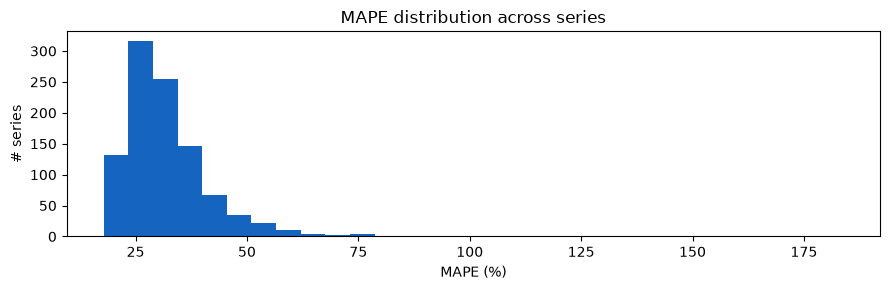

In [10]:
# Sanity visualization (optional, nice for screenshots)

import matplotlib.pyplot as plt
metrics_df = pd.DataFrame(metrics, columns=["sku_id", "warehouse_id", "MAPE", "MAE"])
print(metrics_df.describe())

plt.figure(figsize=(9, 3))
plt.hist(metrics_df["MAPE"], bins=30, color="#1565C0")
plt.title("MAPE distribution across series")
plt.xlabel("MAPE (%)"); plt.ylabel("# series")
plt.tight_layout(); plt.show()